In [1]:

!pip install tensorflow opencv-python matplotlib seaborn scikit-learn streamlit grad-cam shap


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 28.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 80.5 MB/s  0:00:00
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=6d9b678efdcb506f75d4aee22bea8c2c44fdcdbd5deb982c5e71f02d8259b8ab
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [grad-cam]


In [3]:

import os

file_path = "/content/B. Disease Grading.zip"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path) / (1024 * 1024), "MB")

    with open(file_path, "rb") as f:
        print("File header:", f.read(20))



File exists: True
File size: 0.6933059692382812 MB
File header: b'PK\x03\x04\n\x00\x00\x00\x00\x00\x85\x83\x98L\x00\x00\x00\x00\x00\x00'


In [4]:

import zipfile

path = "/content/B. Disease Grading.zip"

try:
    with zipfile.ZipFile(path, "r") as z:
        print("ZIP is valid!")
        print("Files inside:", len(z.namelist()))
        print(z.namelist()[:10])
except Exception as e:
    print("ZIP problem:", e)


ZIP problem: File is not a zip file


In [5]:

import os

for file in os.listdir("/content"):
    path = os.path.join("/content", file)
    if os.path.isfile(path):
        print(file, "|", round(os.path.getsize(path)/1024, 2), "KB")


retinal image dataset - Google Search.html | 1024.0 KB


In [6]:

!wget -O /content/IDRiD.zip "https://zenodo.org/records/17219542/files/B.%20Disease%20Grading.zip?download=1"


--2026-11-11 13:53:11--  https://zenodo.org/records/17219542/files/B.%20Disease%20Grading.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 137.138.121.78, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 212405123 (203M) [application/octet-stream]
Saving to: ‘/content/IDRiD.zip’

/content/IDRiD.zip  100%[===================>] 202.56M  1.50MB/s    in 1m 46s  

2026-11-11 13:54:58 (1.92 MB/s) - ‘/content/IDRiD.zip’ saved [212405123/212405123]



In [8]:

import os
print("Downloaded size:", round(os.path.getsize("/content/IDRiD.zip") / (1024*1024), 2), "MB")


Downloaded size: 202.57 MB


In [9]:

import zipfile
import os

zip_path = "/content/IDRiD.zip"
extract_path = "/content/IDRiD"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction successful!")
print(os.listdir(extract_path))


Extraction successful!
['B. Disease Grading']


In [10]:

import os

folder = "/content/IDRiD/B. Disease Grading"

for root, dirs, files in os.walk(folder):
    print("\nFolder:", root)
    print("Files:", files[:8])



Folder: /content/IDRiD/B. Disease Grading
Files: ['LICENSE.txt', 'CC-BY-4.0.txt']

Folder: /content/IDRiD/B. Disease Grading/1. Original Images
Files: []

Folder: /content/IDRiD/B. Disease Grading/1. Original Images/b. Testing Set
Files: ['IDRiD_006.jpg', 'IDRiD_103.jpg', 'IDRiD_100.jpg', 'IDRiD_047.jpg', 'IDRiD_048.jpg', 'IDRiD_086.jpg', 'IDRiD_036.jpg', 'IDRiD_019.jpg']

Folder: /content/IDRiD/B. Disease Grading/1. Original Images/a. Training Set
Files: ['IDRiD_319.jpg', 'IDRiD_199.jpg', 'IDRiD_194.jpg', 'IDRiD_222.jpg', 'IDRiD_147.jpg', 'IDRiD_367.jpg', 'IDRiD_384.jpg', 'IDRiD_270.jpg']

Folder: /content/IDRiD/B. Disease Grading/2. Groundtruths
Files: ['b. IDRiD_Disease Grading_Testing Labels.csv', 'a. IDRiD_Disease Grading_Training Labels.csv']


In [11]:

import pandas as pd
import os

base = "/content/IDRiD/B. Disease Grading/2. Groundtruths"

train_csv = os.path.join(base, "a. IDRiD_Disease Grading_Training Labels.csv")
test_csv = os.path.join(base, "b. IDRiD_Disease Grading_Testing Labels.csv")

train = pd.read_csv(train_csv)
test = pd.read_csv(test_csv)

print("TRAINING DATA")
print(train.head())
print("\nTraining shape:", train.shape)

print("\nTESTING DATA")
print(test.head())
print("\nTesting shape:", test.shape)

print("\nTraining grade counts:")
print(train.iloc[:, 1].value_counts().sort_index())


TRAINING DATA
  Image name  Retinopathy grade  Risk of macular edema   Unnamed: 3  \
0  IDRiD_001                  3                       2         NaN   
1  IDRiD_002                  3                       2         NaN   
2  IDRiD_003                  2                       2         NaN   
3  IDRiD_004                  3                       2         NaN   
4  IDRiD_005                  4                       0         NaN   

   Unnamed: 4  Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8  Unnamed: 9  \
0         NaN         NaN         NaN         NaN         NaN         NaN   
1         NaN         NaN         NaN         NaN         NaN         NaN   
2         NaN         NaN         NaN         NaN         NaN         NaN   
3         NaN         NaN         NaN         NaN         NaN         NaN   
4         NaN         NaN         NaN         NaN         NaN         NaN   

   Unnamed: 10 Unnamed: 11  
0          NaN         NaN  
1          NaN         NaN  
2        

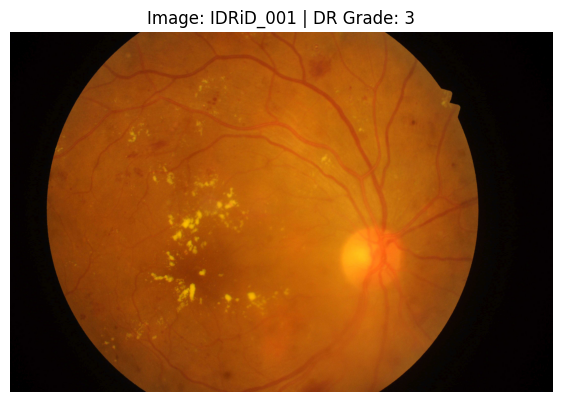

Image loaded successfully!
Image dimensions: (4288, 2848)
Correct disease grade: 3


In [12]:

import os
import matplotlib.pyplot as plt
from PIL import Image

image_folder = "/content/IDRiD/B. Disease Grading/1. Original Images/a. Training Set"

# Select the first image and its label
sample = train.iloc[0]
image_name = sample["Image name"]
grade = int(sample["Retinopathy grade"])

image_path = os.path.join(image_folder, image_name + ".jpg")

# Open and display the image
img = Image.open(image_path)

plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.title(f"Image: {image_name} | DR Grade: {grade}")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image dimensions:", img.size)
print("Correct disease grade:", grade)


In [13]:

import numpy as np
from PIL import Image
import os
from tqdm.notebook import tqdm

image_folder = "/content/IDRiD/B. Disease Grading/1. Original Images/a. Training Set"

X_train = []
y_train = []

for _, row in tqdm(train.iterrows(), total=len(train)):
    image_name = row["Image name"] + ".jpg"
    image_path = os.path.join(image_folder, image_name)

    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    X_train.append(np.array(img))
    y_train.append(int(row["Retinopathy grade"]))

X_train = np.array(X_train, dtype=np.float32) / 255.0
y_train = np.array(y_train)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Preparation completed!")


  0%|          | 0/413 [00:00<?, ?it/s]

Training images: (413, 224, 224, 3)
Training labels: (413,)
Preparation completed!


In [14]:

test_folder = "/content/IDRiD/B. Disease Grading/1. Original Images/b. Testing Set"

X_test = []
y_test = []

for _, row in tqdm(test.iterrows(), total=len(test)):
    image_name = row["Image name"] + ".jpg"
    image_path = os.path.join(test_folder, image_name)

    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    X_test.append(np.array(img))
    y_test.append(int(row["Retinopathy grade"]))

X_test = np.array(X_test, dtype=np.float32) / 255.0
y_test = np.array(y_test)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)
print("Testing preparation completed!")


  0%|          | 0/103 [00:00<?, ?it/s]

Testing images: (103, 224, 224, 3)
Testing labels: (103,)
Testing preparation completed!


In [15]:

import tensorflow as tf
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models

# 1. Divide training data into training and validation sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# 2. Balance the five disease categories
classes = np.unique(y_tr)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_tr
)

class_weights = dict(zip(classes, weights))

# 3. Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

# 4. Build the CNN model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.RandomFlip("horizontal"),
    layers.Rescaling(scale=2.0, offset=-1.0),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax")
])

# 5. Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Train the model
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop]
)

print("CNN training completed!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.3242 - loss: 1.5557 - val_accuracy: 0.3855 - val_loss: 1.3540
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.3515 - loss: 1.4006 - val_accuracy: 0.4940 - val_loss: 1.1604
Epoch 3/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4212 - loss: 1.2414 - val_accuracy: 0.4699 - val_loss: 1.1926
Epoch 4/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4606 - loss: 1.0796 - val_accuracy: 0.5542 - val_loss: 1.0974
Epoch 5/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5091 - loss: 1.0026 - val_accuracy: 0.5060 - val_loss: 1.0949
Epoch 6/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.5061 - loss: 1.0595 - val_accuracy: 0.5181 - val_loss: 1.1187
Epoch 7/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5455 - loss: 0.9276 - val_accuracy: 0.5060 - val_loss: 1.1135
Epoch 8/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 

4/4 ━━━━━━━━━━━━━━━━━━━━ 35s 5s/step
TEST ACCURACY: 49.51 %

CLASSIFICATION REPORT:
                  precision    recall  f1-score   support

           No DR       0.71      0.65      0.68        34
         Mild DR       0.33      0.40      0.36         5
     Moderate DR       0.47      0.44      0.45        32
       Severe DR       0.33      0.47      0.39        19
Proliferative DR       0.44      0.31      0.36        13

        accuracy                           0.50       103
       macro avg       0.46      0.45      0.45       103
    weighted avg       0.51      0.50      0.50       103



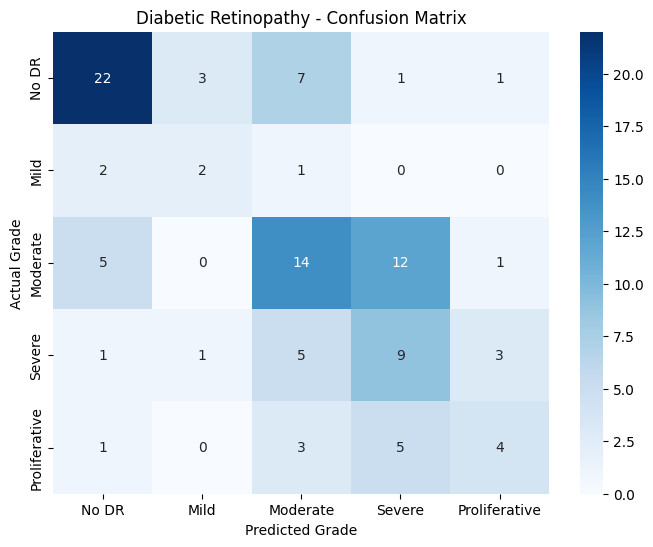

In [16]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predict disease grades on unseen test images
predictions = model.predict(X_test)

# Convert probabilities into predicted grades
y_pred = np.argmax(predictions, axis=1)

# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)

print("TEST ACCURACY:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "No DR",
        "Mild DR",
        "Moderate DR",
        "Severe DR",
        "Proliferative DR"
    ],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3, 4])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No DR", "Mild", "Moderate", "Severe", "Proliferative"],
    yticklabels=["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
)

plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")
plt.title("Diabetic Retinopathy - Confusion Matrix")
plt.show()


In [17]:

model.save("/content/diabetic_retinopathy_model.keras")
print("Model saved successfully!")


Model saved successfully!


In [18]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Select one test image
image = X_test[0]
image_input = np.expand_dims(image, axis=0)

# Get the model's feature maps and prediction
with tf.GradientTape() as tape:
    x = model.layers[2](image_input)
    features = base_model(x, training=False)

    pooled = model.layers[-3](features)
    dropped = model.layers[-2](pooled, training=False)
    predictions = model.layers[-1](dropped)

    predicted_class = tf.argmax(predictions[0])
    loss = predictions[:, predicted_class]

# Calculate gradients
grads = tape.gradient(loss, features)

weights = tf.reduce_mean(grads, axis=(1, 2))
heatmap = tf.reduce_sum(
    weights[:, tf.newaxis, tf.newaxis, :] * features,
    axis=-1
)

heatmap = tf.maximum(heatmap[0], 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()

# Resize heatmap
heatmap = cv2.resize(heatmap, (224, 224))

# Display original and explanation
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Retinal Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image)
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Explanation")
plt.axis("off")

plt.show()

print("Actual grade:", y_test[0])
print("Predicted grade:", int(predicted_class.numpy()))


ValueError: Input 0 with name 'input_layer' of layer 'mobilenetv2_1.00_224' is incompatible with the layer: expected shape=(None, 224, 224, 3), found shape=(1, 7, 7, 1280)

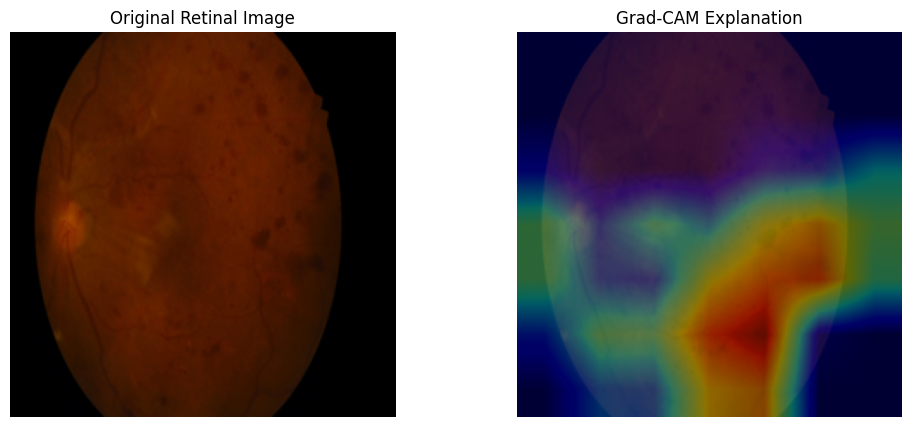

Actual grade: 4
Predicted grade: 4
Grad-CAM completed!


In [19]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Select one test image
image = X_test[0]
image_input = np.expand_dims(image, axis=0)

# Get MobileNetV2 feature extractor
feature_extractor = tf.keras.Model(
    inputs=base_model.input,
    outputs=base_model.get_layer("out_relu").output
)

# Calculate Grad-CAM
with tf.GradientTape() as tape:

    # Apply preprocessing layers once
    x = model.layers[0](image_input, training=False)
    x = model.layers[1](x)

    # Extract feature maps
    features = feature_extractor(x, training=False)
    tape.watch(features)

    # Pass features through classification layers
    pooled = model.layers[-3](features)
    dropped = model.layers[-2](pooled, training=False)
    predictions = model.layers[-1](dropped)

    predicted_class = tf.argmax(predictions[0])
    loss = predictions[:, predicted_class]

# Calculate gradients
grads = tape.gradient(loss, features)

weights = tf.reduce_mean(grads, axis=(1, 2))

heatmap = tf.reduce_sum(
    weights[:, tf.newaxis, tf.newaxis, :] * features,
    axis=-1
)

heatmap = tf.maximum(heatmap[0], 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()

# Resize heatmap
heatmap = cv2.resize(heatmap, (224, 224))

# Display explanation
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Retinal Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image)
plt.imshow(heatmap, cmap="jet", alpha=0.4)
plt.title("Grad-CAM Explanation")
plt.axis("off")

plt.show()

print("Actual grade:", y_test[0])
print("Predicted grade:", int(predicted_class.numpy()))
print("Grad-CAM completed!")


In [20]:

!pip install shap


In [21]:

import shap
import numpy as np
import matplotlib.pyplot as plt

# Function that returns model predictions
def predict_images(images):
    images = np.array(images, dtype=np.float32)
    return model.predict(images, verbose=0)

# Select one retinal image
sample_image = X_test[0:1]

# Create SHAP image masker
masker = shap.maskers.Image("blur(32,32)", (224, 224, 3))

# Create SHAP explainer
explainer = shap.Explainer(
    predict_images,
    masker,
    output_names=[
        "No DR",
        "Mild DR",
        "Moderate DR",
        "Severe DR",
        "Proliferative DR"
    ]
)

# Calculate SHAP values
shap_values = explainer(
    sample_image,
    max_evals=100,
    batch_size=10
)

print("SHAP explanation generated!")


  0%|          | 0/98 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:59, 59.98s/it]               

SHAP explanation generated!


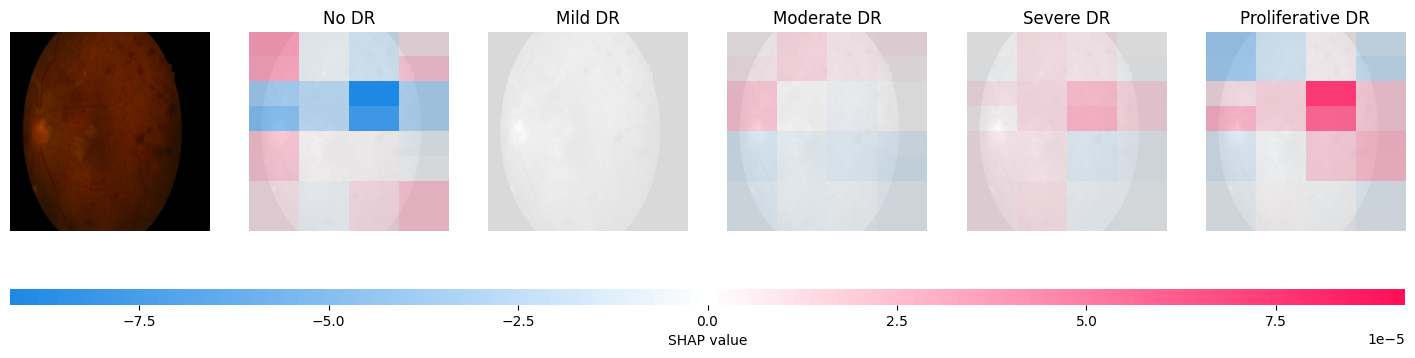

In [22]:

shap.image_plot(shap_values)
